In [1]:
import torch
from torchvision.transforms.functional import to_tensor
from PIL import Image
from SE2TVFlowPyTorch import TV_enhancing
from orientationscore_torch import (
    cakewavelet_stack_fourier,
    wavelet_transform,
)
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["image.cmap"] = "gray"

device = "cpu"

c:\Users\s152030\AppData\Local\anaconda3\envs\torchclean\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# "spiral" "monalisa" "retina"
test = "monalisa"

In [3]:
Or = 16
ξ = 0.2 # Link between spatial and orientational dimensions.
G_inv = (ξ**-2, ξ**-2, 1.) # metric to use to define gradients.

match test:
    case "spiral":
        ground_truth = to_tensor(Image.open("spiral.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noisy = to_tensor(Image.open("noisyspiral.tif").convert("I"))[0].to(dtype=torch.float, device=device) / 255.**2
        t = 1. * ξ
    case "monalisa":
        ground_truth = to_tensor(Image.open("monalisa.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noisy = to_tensor(Image.open("noisymonalisa.tif").convert("I"))[0].to(dtype=torch.float, device=device) / 255.**2
        t = 1. * ξ
    case "retina":
        ground_truth = to_tensor(Image.open("test.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noise = 0.2 * 1. * torch.randn(ground_truth.shape, device=device), (2., 2.)
        noisy = torch.clip(ground_truth + noise, 0., 1.)
        t = 0.2 * ξ

H, W = ground_truth.shape

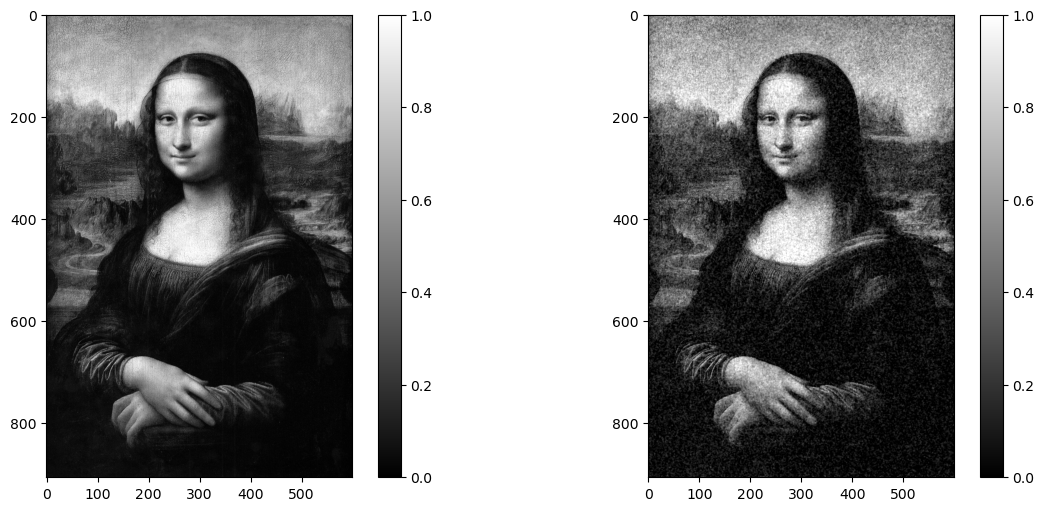

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
cbar = ax[0].imshow(ground_truth.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0])
cbar = ax[1].imshow(noisy.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[1]);

In [5]:
cws_F = cakewavelet_stack_fourier(min(H, W), Or).real.to(device)
U = wavelet_transform(noisy[None, None], cws_F).real[0, 0]

Recon error tensor(0.0010)


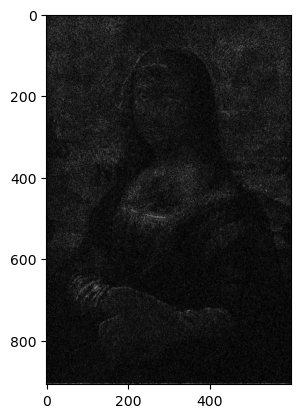

In [6]:
# Test for perfect reconstruction
rec = U.sum(0)

print("Recon error %s"%(( rec-noisy)**2).mean() )

plt.imshow( (rec-noisy).abs().cpu() )
plt.show()

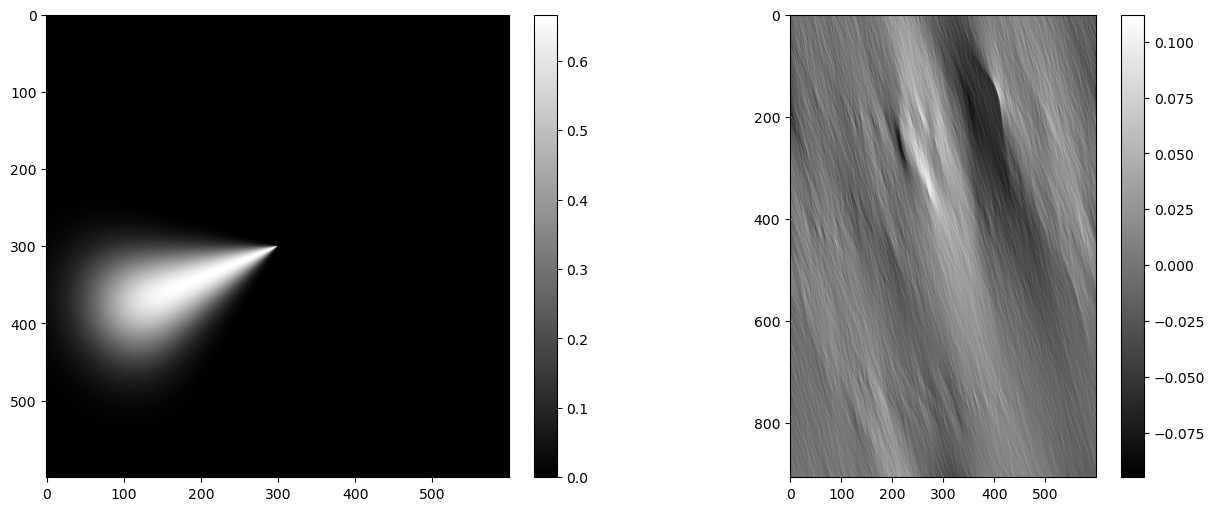

In [7]:
K = 3
fig, ax = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
cbar = ax[0].imshow(cws_F[0, 0, K].cpu())
fig.colorbar(cbar, ax=ax[0])
cbar = ax[1].imshow(U[K].cpu())
fig.colorbar(cbar, ax=ax[1]);

In [8]:
t = 0.079

λ = 50. # For some reason this helps with numerical stability 🤔
U = TV_enhancing(λ * U, t, G_inv, 1., 0.5) / λ

100%|██████████| 20/20 [00:02<00:00,  7.02it/s]


PSNR
tensor(26.5208)


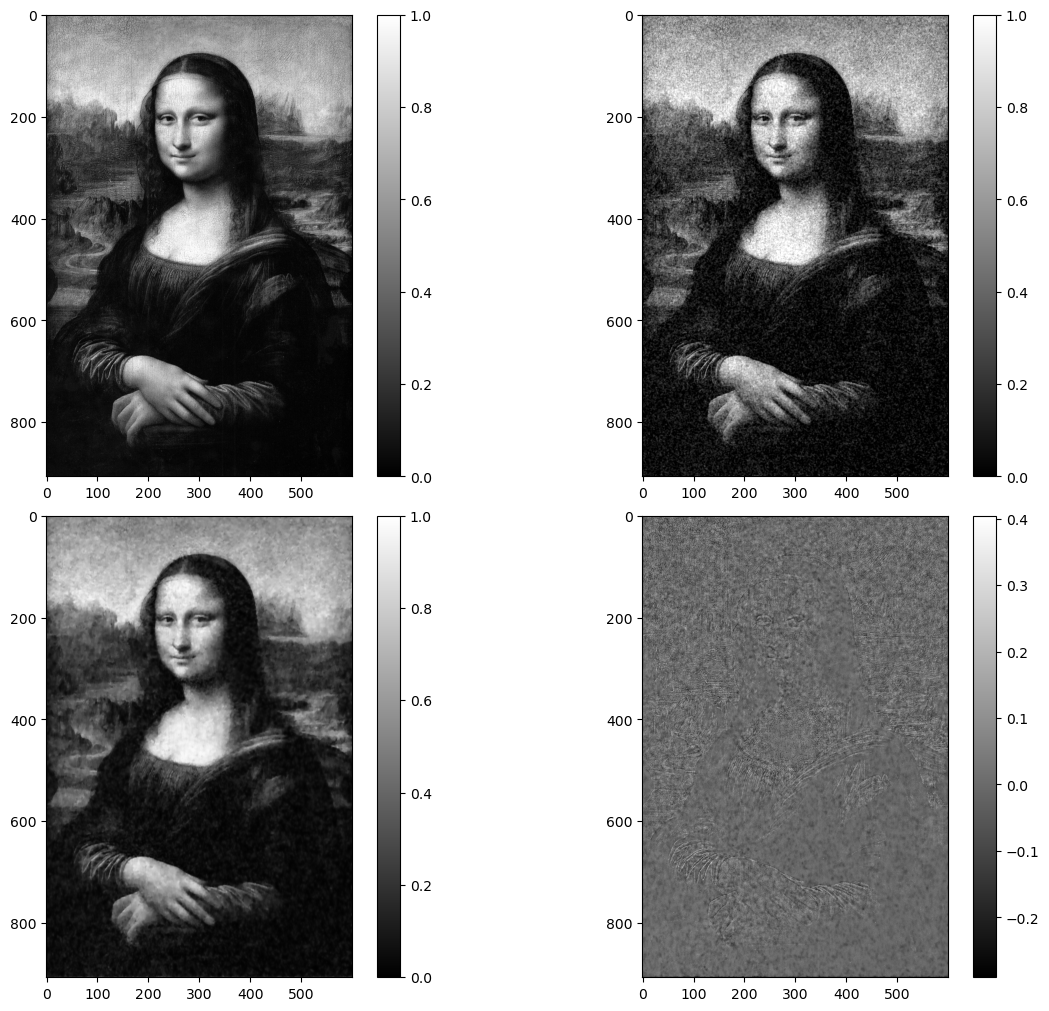

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")
cbar = ax[0, 0].imshow(ground_truth.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0, 0])
cbar = ax[0, 1].imshow(noisy.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0, 1])
cbar = ax[1, 0].imshow(torch.clip(U.sum(0), 0., 1.).cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[1, 0])
cbar = ax[1, 1].imshow((ground_truth - torch.clip(U.sum(0), 0., 1.)).cpu())
fig.colorbar(cbar, ax=ax[1, 1]);

psnr = -10*torch.log10( ((ground_truth - torch.clip(U.sum(0), 0., 1.)).cpu()**2).mean() )
print("PSNR")
print(psnr)

In [10]:
import torch
import numpy as np


def make_callback(args):
    def callback(xk):
        f = loss(xk, *args)
        print(f"loss={f:.6f}")
        print(f"x={xk}")
    return callback



def callback(xk, *args):
    func = loss(xk, *args)
    print(f"x = {xk}, loss = {func}")

def loss(x, *args):
    """ loss
        Description:

            This function is employed for finetuning of the PnP model
        Inputs:
            * x: Parameters to be optimized, in the case of PnP is a mixture
                component \gamma and the threshold level sigma
            * args: Additional optimizaton arguments
                * cnn

    """
    noisy, ground_truth, cws_F, λ, G_inv = args
    #t = 10**x
    t = 10**float(x[0])
    print(t)

    rec = denoise(noisy, cws_F, λ, G_inv, t)
        
    mse =  ((ground_truth - rec)**2).mean().item()
    return( mse )


def denoise(noisy, cws_F, λ, G_inv, t):
    with torch.no_grad():
        U = wavelet_transform(noisy[None, None], cws_F).real[0, 0]
        U = TV_enhancing(λ * U, t, G_inv, 1., 0.5) / λ
        rec = U.sum(0).detach()
    return(rec)



In [11]:
# Let's optimize the value of sig for the deblurring task

from scipy.optimize import minimize


ep = 0.1
x0 = np.log10( np.ones( (1) )*ep )


def scalar_loss(x):
    return loss(np.array([x]), *args)

options = {"disp":True,  "maxiter":20, "maxfev": 40, "fatol":2.0e-7, "xatol": 0.05}
args = (noisy, ground_truth, cws_F, λ, G_inv) 
optimizer = minimize(scalar_loss, x0=x0,
                        method='Nelder-Mead',  options=options, callback=make_callback(args),)  #bounds=bounds,

C:\Users\s152030\AppData\Local\Temp\ipykernel_39048\684963422.py:32: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  t = 10**float(x[0])


0.1


100%|██████████| 25/25 [00:03<00:00,  8.23it/s]


0.08912509381337455


100%|██████████| 22/22 [00:02<00:00,  8.22it/s]


...

0.07943282347242814


100%|██████████| 20/20 [00:02<00:00,  8.57it/s]


loss=0.002228
x=[-1.1]
0.07943282347242814


100%|██████████| 20/20 [00:02<00:00,  8.74it/s]

loss=0.002228
x=[-1.1]
Optimization terminated successfully.
         Current function value: 0.002228
         Iterations: 6
         Function evaluations: 12


In [14]:
10** optimizer.x

array([0.07943282])

In [50]:
for x in [-1., -0.5 , -0.1]:
    print(x, loss(np.array([x]), *args))

100%|██████████| 25/25 [00:03<00:00,  8.16it/s]


-1.0 0.002275138860568404


100%|██████████| 77/77 [00:09<00:00,  8.38it/s]


-0.5 0.0032411820720881224


100%|██████████| 192/192 [00:26<00:00,  7.38it/s]

-0.1 0.004749856889247894


In [27]:
10**0.002228

1.005143341387826

In [ ]:
from scipy.optimize import minimize_scalar


def scalar_loss(x):
    t = 10**x

    rec = denoise(noisy, cws_F, λ, G_inv, t)
    mse = ((ground_truth - rec)**2).mean().item()

    print(f"log10(t)={x:.4f}, t={t:.4e}, mse={mse:.6f}")

    return mse

result = minimize_scalar(
    scalar_loss,
    bounds=(-4, 1),     # example range for log10(t)
    method='bounded',
    options={'xatol': 0.05}
)